<img src="https://raw.githubusercontent.com/drdave-teaching/OPIM5512-notebooks/main/_banners/opim5512_banner.svg" alt="OPIM 5512 banner" width="100%">

# Lab 6A · Your Frozen Model Meets the HRRR
### Same model, different weather in, different load out

*Lab 6, notebook 1 of 3 · Colab · your Lab 5 model, NOAA's HRRR weather model through hefty and dynamical.org*

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/drdave-teaching/OPIM5512-notebooks/blob/main/Module4/Lab6A_Frozen_Model_Meets_HRRR.ipynb)

Your Lab 5 model is **frozen**: it sits in your bucket as `energy/models/model.joblib` and never changes. But every hour
`forecast-24h` feeds it a **weather forecast**, and that forecast is never perfect. Lab 6 is about that uncertainty:

| Notebook | What you do |
|---|---|
| **6A (this one)** | Feed your frozen model a second weather forecast, NOAA's **HRRR**, and see how much the weather moves your load forecast |
| **6B** | Give your model a range: low, expected and high from a random forest and a quantile forest (10th and 90th percentiles) |
| **6C** | Combine the two kinds of uncertainty (your model's and the weather's), ship the range, and get on the Lab 6 leaderboard |

| Part | Time | What you do |
|---|---|---|
| **0. Setup** | 3 min | Install hefty (Colab restarts once) |
| **1. Your frozen model** | 3 min | Load `model.joblib` from your bucket, unchanged |
| **2. Meet the HRRR** | 3 min | NOAA's hourly 3 km weather model, every run since 2018 on dynamical.org |
| **3. hefty** | 5 min | Tomorrow's temperature, wind and sunlight at Bradley in one call |
| **4. The other three inputs** | 5 min | Dew point, humidity and cloud cover from the same HRRR run |
| **5. HRRR vs the National Weather Service** | 5 min | The forecast production uses today next to the HRRR |
| **6. Two load forecasts** | 5 min | Your frozen model on each weather forecast, for the next 24 hours |
| **7. How much does weather error cost?** | 10 min | 2026 backtest: perfect weather vs the HRRR forecast you'd really have had 1, 12 and 24 hours ahead, graded with RTMA |
| **8. The same hour, forecast 8 times** | 5 min | A sneak peek at weather uncertainty for 6C |
| **9. Questions** | 5 min | Short answers (you submit them with 6C) |

**Nothing here touches production.** `forecast-24h` keeps running exactly as you shipped it in Lab 5.

# Part 0 · Setup (3 min)

## 0a. Install hefty
**hefty** is a free Python package by Will Hobbs for getting weather-model forecasts at a point, built for solar and wind
power forecasting ([github.com/williamhobbs/hefty](https://github.com/williamhobbs/hefty)). It reads NOAA and ECMWF
models from several sources. We use **dynamical.org**, a free, no-key archive of weather models stored so that one
location for many runs downloads in seconds.

hefty needs a newer pandas (version 3) than Colab ships, so **the first time you run this cell, Colab installs it and
restarts itself** ("Your session crashed" or "restarting" is expected). Wait for **Connected**, then run the cell again
and keep going. scikit-learn goes back to **1.6.1**, the version your model was saved with.

In [1]:
import importlib.util
import os

ready = importlib.util.find_spec("hefty") is not None and importlib.util.find_spec("dynamical_catalog") is not None
if not ready:
    !pip install -q hefty==0.3.2 dynamical-catalog cartopy
    !pip install -q scikit-learn==1.6.1
    print("Installed. Colab restarts now: wait for 'Connected', then run this cell again.")
    os.kill(os.getpid(), 9)

import hefty
import pandas as pd
import sklearn

print("hefty", hefty.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "(production uses 1.6.1)")

hefty 0.3.2 | pandas 3.1.0 | scikit-learn 1.6.1 (production uses 1.6.1)


## 0b. Your settings
The same two names as Lab 5. Leave them as they are to run in **demo mode** (a stand-in model instead of yours).

In [2]:
PROJECT_ID = "YOUR-ENERGY-PROJECT-ID"     # e.g. "energy-dww05002-f26"
BUCKET_NAME = "YOUR-ENERGY-PROJECT-ID"    # usually the same as your project ID

LAT = 41.9389                             # Bradley International Airport: the same point as your weather scrapers
LON = -72.6832

In [3]:
import io
import json
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
from pandas.tseries.holiday import USFederalHolidayCalendar

warnings.filterwarnings("ignore")
LOCAL = "America/New_York"
DATA = "https://raw.githubusercontent.com/drdave-teaching/OPIM5512-notebooks/main/Module4/data/"
df = pd.read_csv(DATA + "bdl_ct_load_hourly_2023_2026.csv", index_col="hour_utc", parse_dates=["hour_utc"])
print(len(df), "hours of Bradley weather and Connecticut load, from", df["hour_local"].iloc[0], "to", df["hour_local"].iloc[-1])

33215 hours of Bradley weather and Connecticut load, from 2023-01-01 00:00 EST to 2026-10-15 23:00 EDT


## 0c. `make_features`, word for word from Lab 5
The same 11 inputs as production. Only the `weather` table changes in this notebook: what happened, the National
Weather Service forecast, or the HRRR.

In [4]:
WEATHER = ["temp_f", "dewpoint_f", "rel_humidity_pct", "wind_speed_mph", "cloud_cover_pct"]
CALENDAR = ["hour", "day_of_week", "month", "is_weekend", "is_holiday"]
FEATURES = CALENDAR + WEATHER + ["load_yesterday_mw"]


def make_features(hours_utc, weather, load):
    """One row of model inputs per hour.
    hours_utc: the hours to describe (UTC).  weather: table indexed by UTC hour with the WEATHER columns.
    load: Connecticut load in MW, indexed by UTC hour (only hours that are already over)."""
    hours_utc = pd.DatetimeIndex(hours_utc)
    local = hours_utc.tz_convert("America/New_York")
    out = pd.DataFrame(index=hours_utc)
    out["hour"] = local.hour
    out["day_of_week"] = local.dayofweek
    out["month"] = local.month
    out["is_weekend"] = (local.dayofweek >= 5).astype(int)
    holidays = USFederalHolidayCalendar().holidays(start="2020-01-01", end="2030-12-31")
    out["is_holiday"] = local.tz_localize(None).normalize().isin(holidays).astype(int)
    for column in WEATHER:
        out[column] = weather[column].reindex(hours_utc).values
    yesterday = load.reindex(hours_utc - pd.Timedelta(hours=24)).values
    hour_before = load.reindex(hours_utc - pd.Timedelta(hours=25)).values
    out["load_yesterday_mw"] = np.where(np.isnan(yesterday), hour_before, yesterday)
    return out[FEATURES]

# Part 1 · Your frozen model (3 min)
This cell signs you in (pick the Google account that owns your energy project, as in Lab 5) and downloads your live
model and its model card. **Demo mode** trains a stand-in gradient boosting model on 2023 to 2025 instead (about 20
seconds), so the rest of the notebook still runs.

In [5]:
USE_MY_BUCKET = "YOUR-ENERGY-PROJECT-ID" not in PROJECT_ID and "YOUR-ENERGY-PROJECT-ID" not in BUCKET_NAME
local_years = df.index.tz_convert(LOCAL).year
TEST_YEAR = 2026                          # the year your Lab 5 model never saw

if USE_MY_BUCKET:
    from google.colab import auth
    from google.cloud import storage
    auth.authenticate_user()
    bucket = storage.Client(project=PROJECT_ID).bucket(BUCKET_NAME)
    model = joblib.load(io.BytesIO(bucket.blob("energy/models/model.joblib").download_as_bytes()))
    card = json.loads(bucket.blob("energy/models/model_card.json").download_as_text())
    print("Your frozen model:", card.get("model_type"), "| trained", card.get("trained_at"),
          "| Lab 5 test MAE", card.get("test_mae_mw"), "MW")
else:
    from sklearn.ensemble import HistGradientBoostingRegressor
    print("DEMO MODE: training a stand-in model (type your PROJECT_ID and BUCKET_NAME in 0b to use yours)")
    X_all = make_features(df.index, df, df["load_mw"])
    train = local_years < TEST_YEAR
    model = HistGradientBoostingRegressor(random_state=42, early_stopping=True, max_iter=1000, learning_rate=0.1,
                                          max_leaf_nodes=31, validation_fraction=0.1, n_iter_no_change=20,
                                          scoring="neg_mean_absolute_error", tol=0.5)
    model.fit(X_all[train], df["load_mw"][train])
    card = {"model_type": "HistGradientBoostingRegressor (demo)", "trained_at": "demo"}
    print("Stand-in model ready:", model.n_iter_, "trees")

if list(model.feature_names_in_) != FEATURES:
    print("Heads up: your model was trained on", list(model.feature_names_in_), "- this notebook builds", FEATURES)

DEMO MODE: training a stand-in model (type your PROJECT_ID and BUCKET_NAME in 0b to use yours)


Stand-in model ready: 303 trees


# Part 2 · Meet the HRRR (3 min)
The **High-Resolution Rapid Refresh** is NOAA's fastest-updating weather model for the United States:

| | HRRR |
|---|---|
| **Grid** | 3 km squares: Bradley Airport gets its own square, not a 25 km blur |
| **New run** | Every hour. The runs that start at 00, 06, 12 and 18 UTC go out **48 hours**, the others 18 hours |
| **Time step** | **Hourly**, every hour of the run: a real forecast for each hour, nothing filled in between |
| **Ready** | About 1 hour 45 minutes after the run starts (the computer has to finish it first) |
| **Archive** | dynamical.org keeps **every 48-hour run since July 2018**, free, no key |

Your `scraper-weather-forecast` uses the **National Weather Service** forecast for Bradley. That forecast is made by
forecasters who start from models like the HRRR. Today you go one step upstream, to a model itself.

`dynamical_catalog.open` connects to the archive without downloading it (the whole thing is many terabytes); only the
pieces you ask for come down.

In [6]:
import dynamical_catalog

hrrr = dynamical_catalog.open("noaa-hrrr-forecast-48-hour")
inits = pd.DatetimeIndex(hrrr["init_time"].values).tz_localize("UTC")      # when each run started
newest = inits[-1]
now = pd.Timestamp.now(tz="UTC")
age = (now - newest) / pd.Timedelta(hours=1)
print(len(inits), "HRRR 48-hour runs saved, from", inits[0].strftime("%Y-%m-%d"), "to", newest.strftime("%Y-%m-%d %H:%M UTC"))
print("Newest run started", newest.tz_convert(LOCAL).strftime("%a %b %d, %I %p"), "Connecticut time:", round(age, 1), "hours ago")
print("Weather variables in each run:", len(hrrr.data_vars))

12122 HRRR 48-hour runs saved, from 2018-07-13 to 2026-10-29 18:00 UTC
Newest run started Thu Oct 29, 02 PM Connecticut time: 2.0 hours ago
Weather variables in each run: 27


# Part 3 · hefty: tomorrow's temperature, wind and sunlight (5 min)
One call to `get_solar_forecast` gets the newest HRRR run at Bradley:
- `init_date`: which run (the newest one from Part 2)
- `run_length=48`: all 48 hours of it
- `model="hrrr"` and `priority="dynamical"`: the HRRR, from dynamical.org
- `hrrr_hour_middle=False`: keep HRRR's top-of-the-hour values, the same timing as the Bradley observations your
  model learned from

hefty answers in the units weather models use: **°C** and **meters per second**. Your model speaks °F and mph.

In [7]:
from hefty.solar import get_solar_forecast

started = time.time()
h = get_solar_forecast(LAT, LON, newest.tz_localize(None), run_length=48, lead_time_to_start=0, model="hrrr",
                       priority="dynamical", hrrr_hour_middle=False)
print("hefty took", round(time.time() - started), "seconds:", len(h), "hours")

h = h.astype({"temp_air": float, "wind_speed": float, "ghi": float})
sun = pd.DataFrame(index=h.index)
sun["temp_f"] = (h["temp_air"] * 9 / 5 + 32).round(1)             # °C -> °F
sun["wind_speed_mph"] = (h["wind_speed"] * 2.23694).round(1)       # m/s -> mph
sun["solar_wm2"] = h["ghi"].round(0)                               # sunlight on flat ground, watts per square meter
sun.index.name = "hour_utc"
sun.head()

hefty took 15 seconds: 49 hours


,temp_f,wind_speed_mph,solar_wm2
hour_utc,,,
2026-10-29 18:00:00+00:00,66.6,11.4,474.0
2026-10-29 19:00:00+00:00,66.9,11.0,382.0
2026-10-29 20:00:00+00:00,66.6,10.1,245.0
2026-10-29 21:00:00+00:00,64.0,7.1,82.0
2026-10-29 22:00:00+00:00,59.2,6.0,0.0


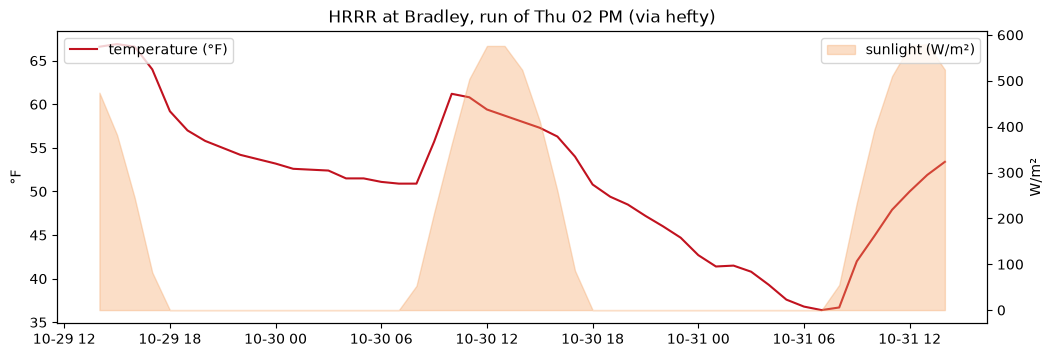

In [8]:
local_time = sun.index.tz_convert(LOCAL).tz_localize(None)
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(local_time, sun["temp_f"], color="#c1121f", label="temperature (°F)")
ax.set_ylabel("°F")
ax2 = ax.twinx()
ax2.fill_between(local_time, sun["solar_wm2"], color="#f4a261", alpha=0.35, label="sunlight (W/m²)")
ax2.set_ylabel("W/m²")
ax.set_title("HRRR at Bradley, run of " + newest.tz_convert(LOCAL).strftime("%a %I %p") + " (via hefty)")
ax.legend(loc="upper left")
ax2.legend(loc="upper right")
plt.show()

**Sunlight is a bonus.** Your model doesn't use it (yet), but rooftop solar panels in Connecticut make the grid's load
**drop** on sunny middays. It comes back in the final project.

# Part 4 · The other three inputs (5 min)
Your model needs **5 weather inputs**. hefty gave us 2 (temperature and wind). It was built for solar and wind power,
so dew point, humidity and cloud cover aren't on its list. They **are** in the same HRRR run on dynamical.org, so we
read them straight from the archive, the same way hefty does inside: turn Bradley's latitude and longitude into the
HRRR's map coordinates (meters on a tilted map, so `cartopy` does the math), then pick the nearest 3 km square.

`hrrr_runs` returns every hour of the runs you ask for, in your model's units, one row per (run, hour).

In [9]:
import cartopy.crs as ccrs

grid = hrrr.spatial_ref.attrs
hrrr_map = ccrs.LambertConformal(central_longitude=grid["longitude_of_central_meridian"],
                                 central_latitude=grid["latitude_of_projection_origin"],
                                 standard_parallels=grid["standard_parallel"],
                                 globe=ccrs.Globe(semimajor_axis=grid["semi_major_axis"], semiminor_axis=grid["semi_minor_axis"]))
X_M, Y_M = hrrr_map.transform_point(LON, LAT, ccrs.PlateCarree())
HRRR_VARS = ["temperature_2m", "dew_point_temperature_2m", "relative_humidity_2m", "wind_u_10m", "wind_v_10m",
             "total_cloud_cover_atmosphere", "downward_short_wave_radiation_flux_surface"]


def hrrr_runs(run_starts):
    """Every hour of the given HRRR runs at Bradley, in your model's units: one row per (run, hour)."""
    run_starts = pd.DatetimeIndex(run_starts).tz_convert("UTC").tz_localize(None)
    raw = hrrr[HRRR_VARS].sel(init_time=run_starts).sel(x=X_M, y=Y_M, method="nearest").load()
    r = raw.to_dataframe().reset_index()
    r[HRRR_VARS] = r[HRRR_VARS].astype(float)                               # 64-bit, so 38.2 prints as 38.2
    out = pd.DataFrame()
    out["init_utc"] = pd.to_datetime(r["init_time"]).dt.tz_localize("UTC")
    out["lead_hours"] = (pd.to_timedelta(r["lead_time"]) / pd.Timedelta(hours=1)).round().astype(int)
    out["hour_utc"] = out["init_utc"] + pd.to_timedelta(out["lead_hours"], unit="h")
    out["temp_f"] = (r["temperature_2m"] * 9 / 5 + 32).round(1)
    out["dewpoint_f"] = (r["dew_point_temperature_2m"] * 9 / 5 + 32).round(1)
    out["rel_humidity_pct"] = r["relative_humidity_2m"].round(1)
    out["wind_speed_mph"] = (np.hypot(r["wind_u_10m"], r["wind_v_10m"]) * 2.23694).round(1)   # wind from its two parts
    out["cloud_cover_pct"] = r["total_cloud_cover_atmosphere"].round(0)
    out["solar_wm2"] = r["downward_short_wave_radiation_flux_surface"].round(0)
    return out


started = time.time()
hrrr_now = hrrr_runs([newest]).set_index("hour_utc")
print("Read", len(hrrr_now), "hours in", round(time.time() - started), "seconds")
check = (hrrr_now["temp_f"] - sun["temp_f"].reindex(hrrr_now.index)).abs().max()
print("Same run, same square as hefty? Largest temperature difference:", round(float(check), 2), "°F")
hrrr_now[WEATHER].head()

Read 49 hours in 5 seconds
Same run, same square as hefty? Largest temperature difference: 0.0 °F


,temp_f,dewpoint_f,rel_humidity_pct,wind_speed_mph,cloud_cover_pct
hour_utc,,,,,
2026-10-29 18:00:00+00:00,66.6,52.5,62.0,11.4,8.0
2026-10-29 19:00:00+00:00,66.9,51.7,59.2,11.0,4.0
2026-10-29 20:00:00+00:00,66.6,51.8,59.0,10.1,1.0
2026-10-29 21:00:00+00:00,64.0,53.6,66.0,7.1,0.0
2026-10-29 22:00:00+00:00,59.2,53.6,75.5,6.0,0.0


> **Contribute to hefty.** hefty's dynamical.org reader translates a short list of variable names (`mapping_in` in
> `get_fcast_dataframe`, file `hefty/utilities.py`): temperature, wind, sunlight and pressure. Adding
> `dew_point_temperature_2m`, `relative_humidity_2m` and `total_cloud_cover_atmosphere` would make it useful for
> **energy demand** forecasting, not just solar and wind. That's a small, real open-source pull request. Will Hobbs, the
> author, welcomes contributions: start with an issue at
> [github.com/williamhobbs/hefty/issues](https://github.com/williamhobbs/hefty/issues).

# Part 5 · HRRR vs the National Weather Service (5 min)
This cell downloads the NWS forecast for Bradley right now, the same file your `scraper-weather-forecast` saves every
hour, and lines it up with the HRRR for the **next 24 full hours** (the hours `forecast-24h` forecasts).

In [10]:
import xml.etree.ElementTree as ET

import requests

NWS_FIELDS = {("temperature", "hourly"): "temp_f", ("temperature", "dew point"): "dewpoint_f",
              ("humidity", "relative"): "rel_humidity_pct", ("wind-speed", "sustained"): "wind_speed_mph",
              ("cloud-amount", "total"): "cloud_cover_pct"}
url = "https://forecast.weather.gov/MapClick.php?lat=" + str(LAT) + "&lon=" + str(LON) + "&FcstType=digitalDWML"
root = ET.fromstring(requests.get(url, headers={"User-Agent": "OPIM5512-student (UConn)"}, timeout=60).text)
nws_issued = pd.Timestamp(root.find(".//creation-date").text).tz_convert("UTC")
starts = []
for t in root.iter("start-valid-time"):
    starts.append(pd.Timestamp(t.text).tz_convert("UTC"))
nws = pd.DataFrame(index=pd.DatetimeIndex(starts, name="hour_utc"))
for element in root.iter():
    key = (element.tag, element.get("type"))
    if key in NWS_FIELDS:
        values = []
        for v in element.findall("value"):
            if v.text in (None, ""):
                values.append(np.nan)
            else:
                values.append(float(v.text))
        if len(values) == len(nws):
            nws[NWS_FIELDS[key]] = values

this_hour = now.floor("h")
targets = pd.date_range(this_hour + pd.Timedelta(hours=1), periods=24, freq="h")
print("NWS forecast issued", nws_issued.tz_convert(LOCAL).strftime("%a %I:%M %p"), "| HRRR run of",
      newest.tz_convert(LOCAL).strftime("%a %I %p"), "| next 24 hours:", targets[0].tz_convert(LOCAL).strftime("%a %I %p"),
      "to", targets[-1].tz_convert(LOCAL).strftime("%a %I %p"))

NWS forecast issued Thu 02:28 PM | HRRR run of Thu 02 PM | next 24 hours: Thu 04 PM to Fri 03 PM


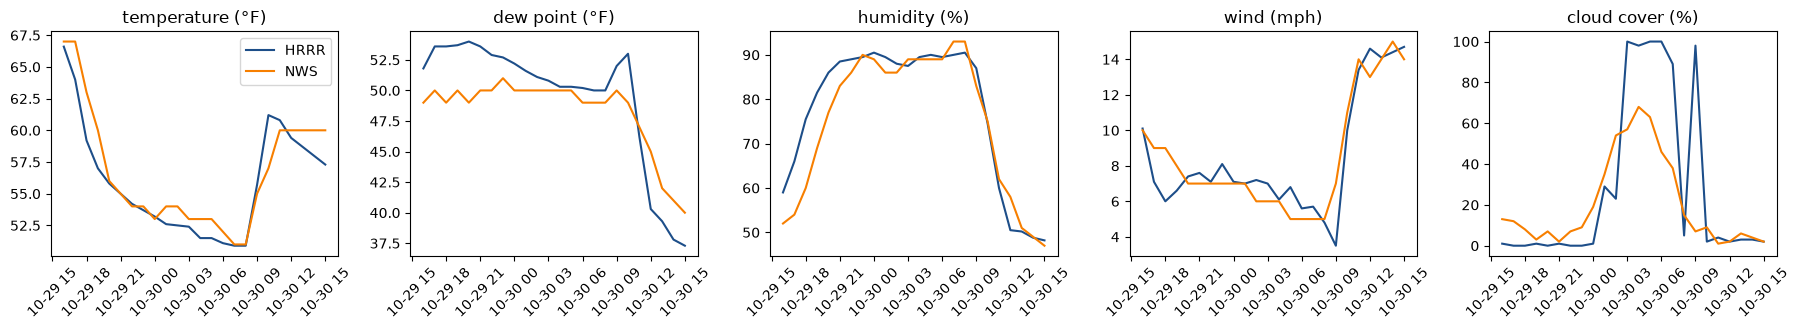

,average difference (HRRR - NWS),largest difference
temp_f,-0.8,4.2
dewpoint_f,1.2,5.0
rel_humidity_pct,2.5,15.5
wind_speed_mph,-0.1,3.5
cloud_cover_pct,7.3,91.0


In [11]:
labels = {"temp_f": "temperature (°F)", "dewpoint_f": "dew point (°F)", "rel_humidity_pct": "humidity (%)",
          "wind_speed_mph": "wind (mph)", "cloud_cover_pct": "cloud cover (%)"}
target_local = targets.tz_convert(LOCAL).tz_localize(None)
fig, axes = plt.subplots(1, 5, figsize=(18, 3.4))
for i in range(5):
    column = WEATHER[i]
    axes[i].plot(target_local, hrrr_now[column].reindex(targets), color="#1d4e89", label="HRRR")
    axes[i].plot(target_local, nws[column].reindex(targets), color="#f77f00", label="NWS")
    axes[i].set_title(labels[column])
    axes[i].tick_params(axis="x", labelrotation=45)
axes[0].legend()
plt.tight_layout()
plt.show()

gap = pd.DataFrame(index=WEATHER)
gap["average difference (HRRR - NWS)"] = (hrrr_now[WEATHER].reindex(targets) - nws[WEATHER].reindex(targets)).mean().round(1)
gap["largest difference"] = (hrrr_now[WEATHER].reindex(targets) - nws[WEATHER].reindex(targets)).abs().max().round(1)
gap

Two professional forecasts for the same airport, the same day. Temperature usually agrees within a few degrees.
**Cloud cover** often doesn't: a model's cloud percent and a forecaster's sky cover are measured differently (Lab 5's
"sky in two sources" section), so a big cloud gap isn't always an error.

# Part 6 · Two load forecasts (5 min)
Same frozen model, same 24 hours, same calendar and same `load_yesterday_mw`. **Only the weather is different.**
With your bucket, yesterday's load comes from your `scraper-isone` (exactly like `forecast-24h`). In demo mode it's a
stand-in: the typical load for that Connecticut hour over the last four weeks of the Lab 5 file.

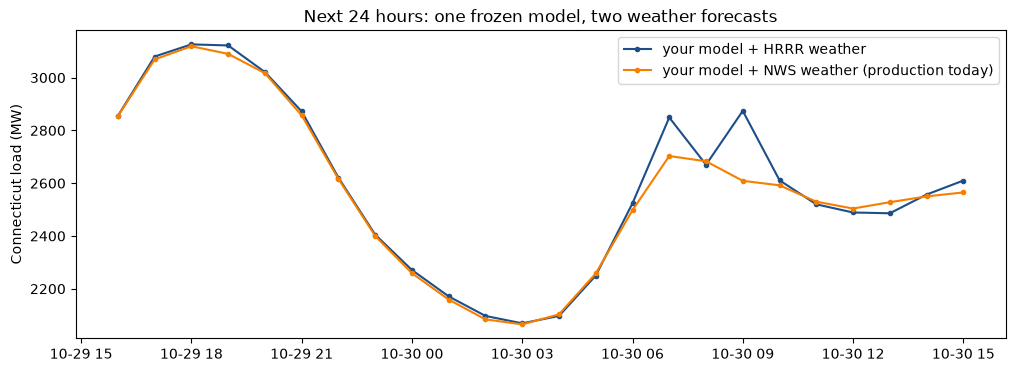

Average gap: 30 MW | largest: 265 MW at Fri 09 AM


In [12]:
if USE_MY_BUCKET:
    load_table = pd.read_csv(io.BytesIO(bucket.blob("energy/datasets/ct_load_5min_hourly_master.csv").download_as_bytes()))
    load_table["hour_utc"] = pd.to_datetime(load_table["hour_utc"], utc=True)
    recent_load = load_table.set_index("hour_utc")["load_mw_5min_avg"].sort_index()
else:
    last_month = df["load_mw"].iloc[-28 * 24:]
    typical = last_month.groupby(last_month.index.tz_convert(LOCAL).hour).mean()
    past_hours = pd.date_range(this_hour - pd.Timedelta(hours=48), this_hour, freq="h")
    recent_load = pd.Series(typical.reindex(past_hours.tz_convert(LOCAL).hour).values, index=past_hours)

forecasts = pd.DataFrame(index=targets)
for name, weather in [("HRRR", hrrr_now), ("NWS", nws)]:
    X = make_features(targets, weather, recent_load)
    X[WEATHER] = X[WEATHER].interpolate(limit_direction="both")       # the same honest gap filling as forecast-24h
    X["load_yesterday_mw"] = X["load_yesterday_mw"].fillna(float(recent_load.iloc[-1]))
    forecasts[name] = model.predict(X[FEATURES]).round(0)
forecasts["HRRR - NWS"] = forecasts["HRRR"] - forecasts["NWS"]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(target_local, forecasts["HRRR"], color="#1d4e89", marker="o", markersize=3, label="your model + HRRR weather")
ax.plot(target_local, forecasts["NWS"], color="#f77f00", marker="o", markersize=3, label="your model + NWS weather (production today)")
ax.set_ylabel("Connecticut load (MW)")
ax.set_title("Next 24 hours: one frozen model, two weather forecasts")
ax.legend()
plt.show()
biggest = forecasts["HRRR - NWS"].abs().idxmax()
print("Average gap:", round(float(forecasts["HRRR - NWS"].abs().mean())), "MW | largest:",
      round(float(forecasts.loc[biggest, "HRRR - NWS"])), "MW at", biggest.tz_convert(LOCAL).strftime("%a %I %p"))

Which one is right? Nobody knows yet: that's tomorrow's leaderboard. But now you know how far apart they are, and that
**gap is weather uncertainty**, flowing straight through your model. Part 7 measures it over a whole year instead of one day.

# Part 7 · How much does weather error cost? (10 min)
In Lab 5 your test score (2026) used the weather that **actually happened** at Bradley. Production never has that: it
has a forecast. This part replays 2026 with the HRRR forecast you **really would have had**, hour by hour.

## 7a. The as-issued HRRR archive
Dr. Dave saved every 48-hour HRRR run at Bradley since January 2023 (`bdl_hrrr_asissued_2023_2026.csv.gz`, built with
the same `hrrr_runs` reader as Part 4): one row per (run, hour ahead), 0 to 48 hours ahead. *As issued* means exactly
the numbers that were published at the time, never updated with hindsight.

In [13]:
archive = pd.read_csv(DATA + "bdl_hrrr_asissued_2023_2026.csv.gz", parse_dates=["init_utc", "hour_utc"])
print(len(archive), "rows:", archive["init_utc"].nunique(), "runs from", archive["init_utc"].min().strftime("%Y-%m-%d"),
      "to", archive["init_utc"].max().strftime("%Y-%m-%d %H:%M UTC"))
archive.head()

273958 rows: 5591 runs from 2023-01-01 to 2026-10-29 12:00 UTC


,init_utc,lead_hours,hour_utc,temp_f,dewpoint_f,rel_humidity_pct,wind_speed_mph,cloud_cover_pct,solar_wm2
0,2023-01-01 00:00:00+00:00,0,2023-01-01 00:00:00+00:00,48.6,48.3,94.5,3.0,100.0,0.0
1,2023-01-01 00:00:00+00:00,1,2023-01-01 01:00:00+00:00,48.6,48.5,97.0,3.0,100.0,0.0
2,2023-01-01 00:00:00+00:00,2,2023-01-01 02:00:00+00:00,48.5,48.4,98.0,2.8,100.0,0.0
3,2023-01-01 00:00:00+00:00,3,2023-01-01 03:00:00+00:00,48.6,48.4,98.0,3.4,100.0,0.0
4,2023-01-01 00:00:00+00:00,4,2023-01-01 04:00:00+00:00,48.8,48.8,98.0,4.0,100.0,0.0


## 7b. "The forecast you'd have had"
For a target hour and a lead time (say 12 hours ahead), the honest HRRR forecast is the **newest run that was ready**
12 hours before that hour. A run is ready about 2 hours after it starts, and 48-hour runs start every 6 hours, so 12
hours ahead you're really using a run that started 14 to 20 hours earlier.

In [14]:
READY_HOURS = 2                           # a run is published about 1 h 45 min after it starts


def hrrr_as_issued(target_hours, hours_ahead):
    """For each target hour: the HRRR forecast you would have had hours_ahead hours earlier, from the newest
    48-hour run that was ready by then. If that run is missing from the archive, the run before it."""
    issued = target_hours - pd.Timedelta(hours=hours_ahead)
    run = (issued - pd.Timedelta(hours=READY_HOURS)).floor("6h")             # runs start at 00, 06, 12, 18 UTC
    table = pd.DataFrame(np.nan, index=target_hours, columns=WEATHER)
    for back in range(3):                                                    # newest ready run, else 6 h older, else 12
        wanted = pd.DataFrame({"init_utc": run - pd.Timedelta(hours=6 * back), "hour_utc": target_hours})
        found = wanted.merge(archive, on=["init_utc", "hour_utc"], how="left")
        empty = table["temp_f"].isna().values
        table.loc[empty, WEATHER] = found.loc[empty, WEATHER].values
    return table


test_hours = df.index[(local_years == TEST_YEAR) & (df.index <= archive["hour_utc"].max())]
example = test_hours[len(test_hours) // 2]           # an hour in the middle of the test year
print("Example: the forecast for", example.tz_convert(LOCAL).strftime("%b %d, %I %p"), "Connecticut time")
for ahead in [1, 12, 24]:
    used = (example - pd.Timedelta(hours=ahead) - pd.Timedelta(hours=READY_HOURS)).floor("6h")
    print("  made", ahead, "h ahead uses the run of", used.tz_convert(LOCAL).strftime("%b %d, %I %p"),
          "(" + str(int((example - used) / pd.Timedelta(hours=1))) + " h into that run):",
          hrrr_as_issued(pd.DatetimeIndex([example]), ahead)["temp_f"].iloc[0], "°F | actual",
          df.loc[example, "temp_f"], "°F")

Example: the forecast for May 25, 12 AM Connecticut time
  made 1 h ahead uses the run of May 24, 08 PM (4 h into that run): 54.5 °F | actual 53.0 °F
  made 12 h ahead uses the run of May 24, 08 AM (16 h into that run): 52.4 °F | actual 53.0 °F


  made 24 h ahead uses the run of May 23, 08 PM (28 h into that run): 51.2 °F | actual 53.0 °F


## 7c. RTMA, the weather "answer key"
To grade a weather forecast you need the truth. The Bradley station is one thermometer with gaps (Lab 5 had to fill
them). **RTMA** (Real-Time Mesoscale Analysis) is NOAA's best map of what **actually happened** each hour: every
station plus a model, on a 2.5 km grid, every hour since 2017, never a gap. NOAA uses it to grade its own forecasts.
`bdl_rtma_temp_2023_2026.csv` is the RTMA temperature for the square at Bradley.

In [15]:
rtma = pd.read_csv(DATA + "bdl_rtma_temp_2023_2026.csv", index_col="hour_utc", parse_dates=["hour_utc"])
print(len(rtma), "RTMA hours, from", rtma.index.min().strftime("%Y-%m-%d"), "to", rtma.index.max().strftime("%Y-%m-%d %H:%M UTC"))
both = df.index.intersection(rtma.index)
station_vs_rtma = (df.loc[both, "temp_f"] - rtma.loc[both, "temp_f"]).abs().mean()
print("Even two kinds of 'what happened' disagree: Bradley station vs RTMA temperature,",
      round(float(station_vs_rtma), 1), "°F apart on average")

18424 RTMA hours, from 2023-01-01 to 2026-10-29 16:00 UTC
Even two kinds of 'what happened' disagree: Bradley station vs RTMA temperature, 1.1 °F apart on average


## 7d. The bill
Your frozen model on 2026, four ways. Only the weather table changes; the hours, the calendar and yesterday's load
are identical.

In [16]:
y_true = df.loc[test_hours, "load_mw"]
sources = {"what happened at Bradley (your Lab 5 test score)": df}
for ahead in [1, 12, 24]:
    sources["HRRR, forecast " + str(ahead) + " h ahead"] = hrrr_as_issued(test_hours, ahead)

predictions = {}
usable = pd.Series(True, index=test_hours)
for name in sources:
    X = make_features(test_hours, sources[name], df["load_mw"])
    usable = usable & X[WEATHER].notna().all(axis=1)
    predictions[name] = X
rows = []
for name in sources:
    X = predictions[name][usable]
    pred = model.predict(X[FEATURES])
    rows.append({"weather fed to your model": name,
                 "temperature off by (°F)": round(float((X["temp_f"] - df.loc[X.index, "temp_f"]).abs().mean()), 1),
                 "load MAE (MW)": round(float(np.mean(np.abs(y_true[usable].values - pred))), 1)})
bill = pd.DataFrame(rows).set_index("weather fed to your model")
bill["cost of the weather (MW)"] = (bill["load MAE (MW)"] - bill["load MAE (MW)"].iloc[0]).round(1)
print(int(usable.sum()), "test hours in 2026 (temperature compared with the Bradley station)")
bill

6911 test hours in 2026 (temperature compared with the Bradley station)


,temperature off by (°F),load MAE (MW),cost of the weather (MW)
weather fed to your model,,,
what happened at Bradley (your Lab 5 test score),0.0,120.4,0.0
"HRRR, forecast 1 h ahead",2.2,139.5,19.1
"HRRR, forecast 12 h ahead",2.6,149.4,29.0
"HRRR, forecast 24 h ahead",2.8,156.8,36.4


**Read the bill:**
- Row 1 is the Lab 5 test score: perfect weather, a score production can never get.
- The HRRR rows are what production **really** gets. The difference is the **cost of the weather**, in MW, and it
  grows the further ahead you forecast. The leaderboard scores leads 1 to 24 hours, so your live score sits somewhere
  in between.
- Part of the HRRR's "error" isn't the forecast's fault: your model learned **Bradley station** weather, and the HRRR
  describes a 3 km square around it. 7e shows how big that station-vs-grid gap is.

## 7e. How fast does a forecast go stale?
Every 2026 HRRR run, graded against RTMA (and against the Bradley station), by how many hours ahead it was forecasting.

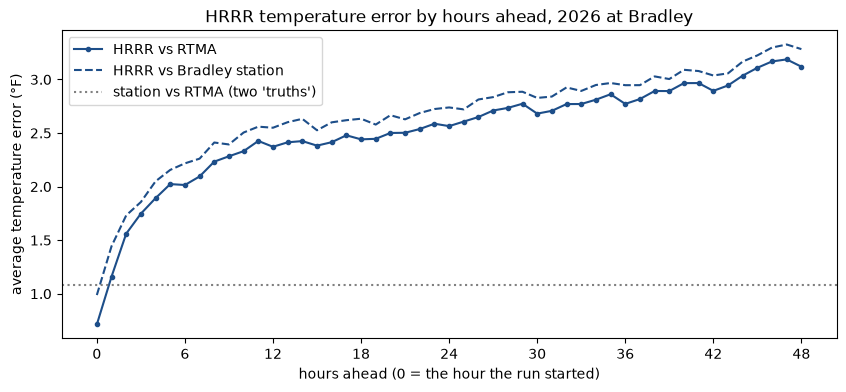

1 hour ahead: 1.2 °F | 24 hours: 2.6 °F | 48 hours: 3.1 °F


In [17]:
graded = archive[archive["hour_utc"].dt.tz_convert(LOCAL).dt.year == TEST_YEAR].set_index("hour_utc")
graded["error_vs_rtma"] = (graded["temp_f"] - rtma["temp_f"].reindex(graded.index)).abs()
graded["error_vs_station"] = (graded["temp_f"] - df["temp_f"].reindex(graded.index)).abs()
by_lead = graded.groupby("lead_hours")[["error_vs_rtma", "error_vs_station"]].mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(by_lead.index, by_lead["error_vs_rtma"], color="#1d4e89", marker="o", markersize=3, label="HRRR vs RTMA")
ax.plot(by_lead.index, by_lead["error_vs_station"], color="#1d4e89", linestyle="--", label="HRRR vs Bradley station")
ax.axhline(station_vs_rtma, color="gray", linestyle=":", label="station vs RTMA (two 'truths')")
ax.set_xlabel("hours ahead (0 = the hour the run started)")
ax.set_ylabel("average temperature error (°F)")
ax.set_title("HRRR temperature error by hours ahead, 2026 at Bradley")
ax.set_xticks(range(0, 49, 6))
ax.legend()
plt.show()
print("1 hour ahead:", round(float(by_lead.loc[1, "error_vs_rtma"]), 1), "°F | 24 hours:",
      round(float(by_lead.loc[24, "error_vs_rtma"]), 1), "°F | 48 hours:", round(float(by_lead.loc[48, "error_vs_rtma"]), 1), "°F")

The line climbs slowly but surely, and it wiggles with the time of day: the error is a little bigger at some hours of
the day than others (look for the bumps every 24 hours). Notice the dashed line sits above the solid one: part of
the "error" against the station is the station-vs-grid gap, not the forecast.

# Part 8 · The same hour, forecast 8 times (5 min)
A new 48-hour HRRR run starts every 6 hours, so **tomorrow afternoon has already been forecast by several runs**: one
made this morning, one last night, one yesterday afternoon, and so on. They don't agree. Feed each one to your frozen
model and you get a **bundle of load forecasts**, all honest, all hourly, from one weather model. Forecasters call this
a *time-lagged ensemble*, and its spread is a measure of weather uncertainty. **6C** turns that spread into part of
your range. (This cell reads 8 runs, so it takes about 2 minutes.)

Read the 8 newest runs in 17 seconds


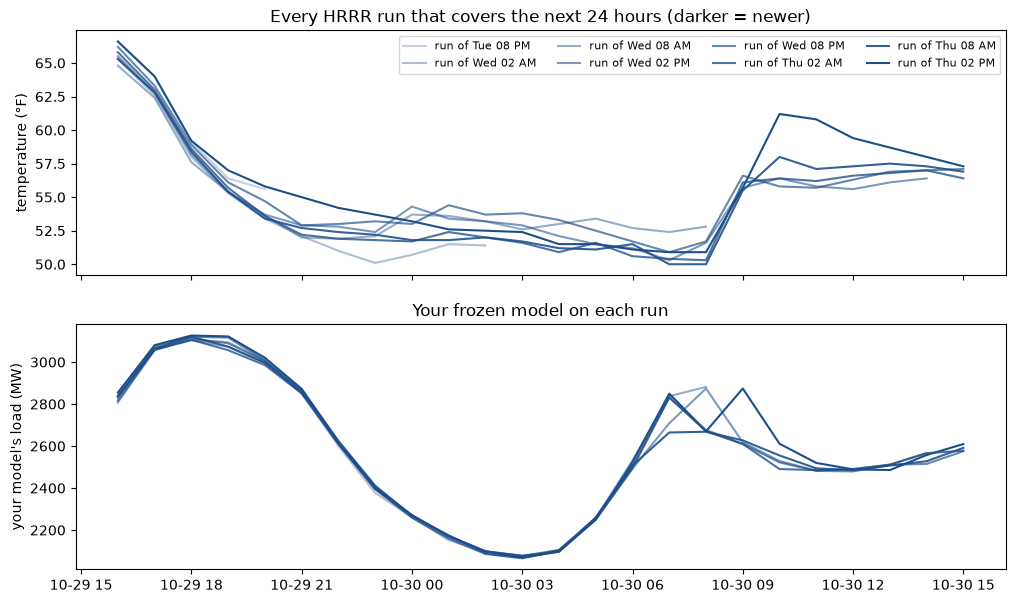

Runs covering each hour: 4 to 8 | average spread (highest minus lowest load): 56 MW


In [18]:
started = time.time()
recent_runs = hrrr_runs(inits[-8:])
print("Read the 8 newest runs in", round(time.time() - started), "seconds")   # about 2 minutes

fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
run_list = inits[-8:]
bundle = pd.DataFrame(index=targets)
for i in range(len(run_list)):
    one = recent_runs[recent_runs["init_utc"] == run_list[i]].set_index("hour_utc")
    covered = targets[targets.isin(one.index)]
    if len(covered) == 0:
        continue
    X = make_features(covered, one, recent_load)
    X["load_yesterday_mw"] = X["load_yesterday_mw"].fillna(float(recent_load.iloc[-1]))
    run_name = run_list[i].tz_convert(LOCAL).strftime("%a %I %p")
    bundle[run_name] = pd.Series(model.predict(X[FEATURES]), index=covered)
    shade = 0.25 + 0.75 * i / (len(run_list) - 1)                 # newer runs are darker
    covered_local = covered.tz_convert(LOCAL).tz_localize(None)
    ax[0].plot(covered_local, one.loc[covered, "temp_f"], color="#1d4e89", alpha=shade, label="run of " + run_name)
    ax[1].plot(covered_local, bundle.loc[covered, run_name], color="#1d4e89", alpha=shade)
ax[0].set_ylabel("temperature (°F)")
ax[0].set_title("Every HRRR run that covers the next 24 hours (darker = newer)")
ax[0].legend(fontsize=8, ncol=4)
ax[1].set_ylabel("your model's load (MW)")
ax[1].set_title("Your frozen model on each run")
plt.show()
spread = bundle.max(axis=1) - bundle.min(axis=1)
print("Runs covering each hour:", int(bundle.notna().sum(axis=1).min()), "to", int(bundle.notna().sum(axis=1).max()),
      "| average spread (highest minus lowest load):", round(float(spread.mean())), "MW")

Notice the runs usually **fan out** further ahead and agree more for the next few hours. Not always, though: sometimes
the newest run jumps away from all the older ones (a front arrives early, a sea breeze shows up). That fan is the
weather half of the uncertainty. Your model's own mistakes are the other half: that's 6B.

# Part 9 · Questions (5 min)
Answer in a sentence or two each. You'll paste them into **Submit Lab 6** at the end of 6C.

1. **Part 2:** How old was the newest HRRR 48-hour run when you ran it? Why can't the newest run ever be from "right now"?
2. **Part 6:** What was the largest gap between your HRRR and NWS load forecasts, and at what hour? Which weather input
   (Part 5) do you think caused it?
3. **Part 7d:** How many MW does weather error cost your model 24 hours ahead, compared with perfect weather? Why does your
   live leaderboard score look worse than your Lab 5 test score?
4. **Part 7e and Part 8:** How do temperature errors and the spread between runs change as you forecast further ahead?
   What does that suggest about how wide your range should be at 1 hour ahead vs 24 hours ahead?

*Your answers:*

---

**Next: 6B**, where your model learns to say how sure it is: low, expected and high for every hour.